<a href="https://colab.research.google.com/github/alexmordashov/image_processing/blob/main/%D0%A0%D0%B0%D0%B1%D0%BE%D1%82%D0%B0%20%E2%84%969/%D0%9F%D1%80%D0%BE%D0%B5%D0%BA%D1%82%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%963_%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F_%D0%B8_%D0%B4%D0%B5%D1%82%D0%B5%D0%BA%D1%86%D0%B8%D1%8F_%D0%BE%D0%B1%D1%8A%D0%B5%D0%BA%D1%82%D0%BE%D0%B2_%D0%BD%D0%B0_%D0%B8%D0%B7%D0%BE%D0%B1%D1%80%D0%B0%D0%B6%D0%B5%D0%BD%D0%B8%D0%B8_%D1%81_%D0%B8%D1%81%D0%BF%D0%BE%D0%BB%D1%8C%D0%B7%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%D0%BC_%D0%B1%D0%B8%D0%B1%D0%BB%D0%B8%D0%BE%D1%82%D0%B5%D0%BA%D0%B8_ImageAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Проектная работа №3. Классификация и детекция объектов на изображении с использованием библиотеки ImageAI**

## **Введение**

До этого момента мы с вами разбирались, как работать с изображениями "вручную" - писали алгоритмы бинаризации, применяли фильтры, операторы Канни и Собеля, выделяли признаки и формировали строгие условия для классификации. В общем, учились понимать структуру изображения без использования машинного обучения. Работали в основном со статичными изображениями.

В данной работе с библиотекой ImageAI - вы воспользуетесь готовыми ML-моделями для детекции и классификации объектов.



**Зачем нам это нужно на данном этапе:**

1. В реальной работе вы часто будете использовать готовые решения - надо уметь с ними работать. Но главное - рассматривайте эту работу как пример того, как нужно формировать свои собственные готовые решения. По сути, ваш алгоритм должен быть упакован как функция, которая получает на вход данные, обрабатывает их и выдает результат обработки - именно так устроены все профессиональные библиотеки.

2. Вы сможете сравнить: что дают классические методы, которые мы программировали, и что дают нейросети. Увидите плюсы и минусы каждого подхода.

3. Научитесь работать не только со статичными изображениями, но и с видеопотоком - обработка видеофайлов, работа с веб-камерой прямо в Colab.

Понимание того, как работают классические алгоритмы, которые мы рассматривали ранее и будем рассматривать в будущем, позволит вам не просто использовать готовые модели как черный ящик, а понимать, что происходит внутри, и когда какой подход лучше применять.


---

Ссылка на страницу с технической документацией: https://imageai.readthedocs.io/en/latest/index.html

- *ImageAI — это Python-библиотека, созданная для того, чтобы дать разработчикам, исследователям и студентам возможность создавать приложения и системы с автономными возможностями глубокого обучения и компьютерного зрения с использованием простого и небольшого количества строк кода.*

**Перечень объектов, которые идентифицирует ImageAI:**

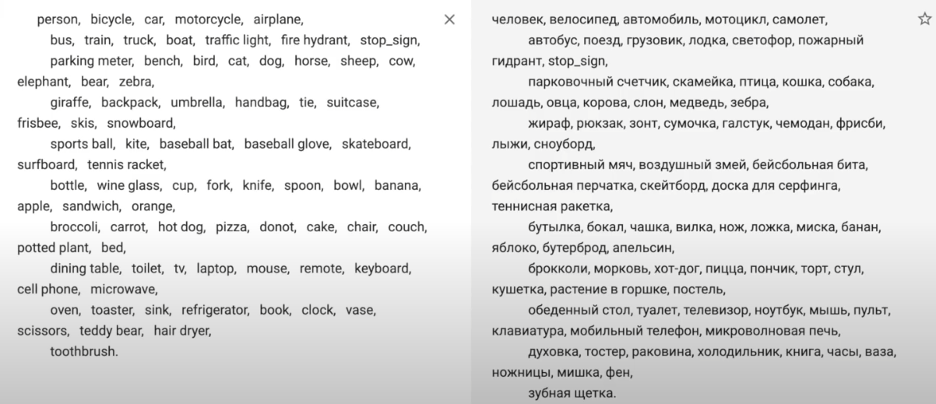

# **Примеры работы с библиотекой:**

In [ ]:
!pip install imageai # установка библиотеки ImageAI

# Добавляем в проект исходное изображение:

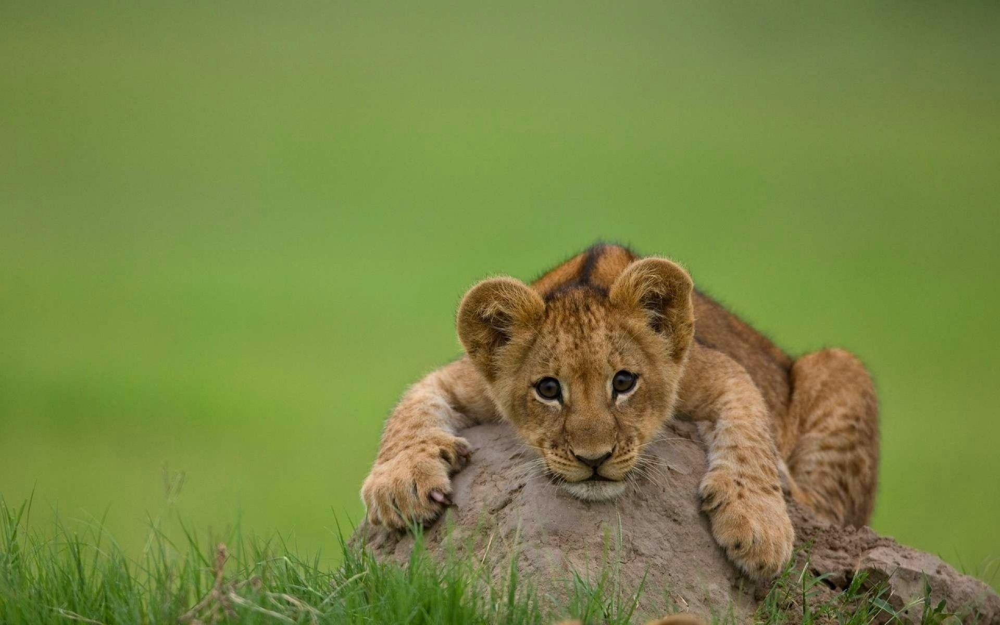

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from google.colab.patches import cv2_imshow
from urllib.request import urlopen
req = urlopen('https://img.youscreen.ru/wall/14977257054998/14977257054998_1920x1200.jpg') # используя метод urlopen, получаем объект запроса по ссылке (изображение)
                                                                                      # и сохраняем его в виде потокового набора данных в переменную "req"

image_2 = np.asarray(bytearray(req.read()), dtype=np.uint8) # преобразуем потоковый набор данных в массив numpy
image_2 = cv2.imdecode(image_2, -1) # декодируем изображение в привычный для отображения формат

cv2_imshow(image_2) # Выводим изображение, используя метод cv2_imshow()

# Пример №1. Детекция

[Техническая документация](https://imageai.readthedocs.io/en/latest/detection/index.html)

In [ ]:
import requests

model_file = requests.get("https://github.com/OlafenwaMoses/ImageAI/releases/download/3.0.0-pretrained/retinanet_resnet50_fpn_coco-eeacb38b.pth/").content
with open('/content/retinanet_resnet50_fpn_coco-eeacb38b.pth', 'wb') as f:
    f.write(model_file)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained_backbone' is deprecated since 0.13 and may be removed in the future, please use 'weights_backbone' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights_backbone' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to 

[{'name': 'cat', 'percentage_probability': 87.99, 'box_points': [694, 479, 1705, 1116]}]


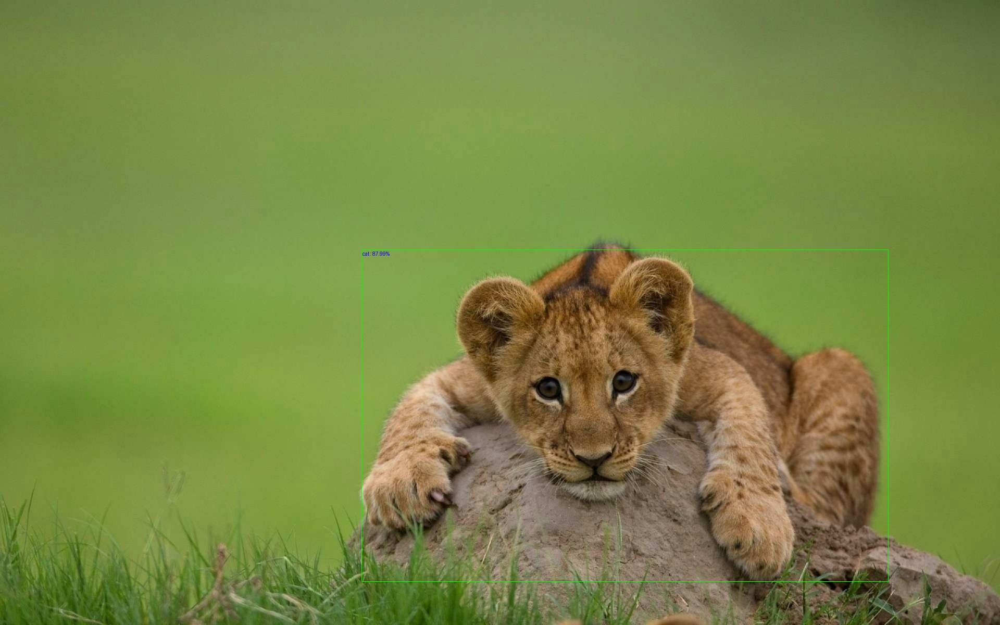

In [ ]:
from imageai.Detection import ObjectDetection # Импортируем из библиотеки imageai класс ObjectDetection для поиска объектов
import os # Импортируем библиотеку os для взаимодействия с ОС

exec_path = os.getcwd()# Объявляем переменную exec_path и помещаем в неё функцию os.getcwd()для указания пути к данному проекту (для удобства работы с файлами, находящимися в корневой папке проекта)

detector = ObjectDetection() # создаем объект класса ObjectDetection
detector.setModelTypeAsRetinaNet() # обращаемся к методу setModelTypeAsRetinaNet, тем самым устанавливая для использования в проекте модель RetinaNet для распознавания объектов
detector.setModelPath("/content/retinanet_resnet50_fpn_coco-eeacb38b.pth") # указываем путь к модели (предварительно модель необходимо скачать с официального сайта ImageAI и поместить в корневую папку проекта)
detector.loadModel() # загружаем модель

list_objcs = detector.detectObjectsFromImage( # используем метод detectObjectsFromImage для обнаружения объектов на изображении
    input_image=image_2, # указываем путь к исходному изображению, либо имя переменной, которая уже содержит изображение
    output_image_path=os.path.join(exec_path, "new_objects.jpg"), # указываем имя и путь для сохранения распознанного изображения
    minimum_percentage_probability=60, # дополнительная характеристика, отвечающая за процент точности распознавания объекта. В данном случае, если точность объекта будет меньше, чем 60%, то в конечной выборке он присутствовать не будет
    display_percentage_probability=True, # отображение процента точности в конечном изображении
    display_object_name=True # отображение класса объекта в конечном изображении
)

print(list_objcs)
output_image = cv2.imread("/content/new_objects.jpg")
cv2_imshow(output_image)

# Пример №2. Классификация

[Техническая документация](https://imageai.readthedocs.io/en/latest/prediction/index.html)

In [ ]:
from imageai.Classification import ImageClassification
import os

/usr/local/lib/python3.13/dist-packages/torchvision/models/inception.py:43: FutureWarning: The default weight initialization of inception_v3 will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(


##### **Фикс для работы в версии Python 3.13+ (Colab)**

In [ ]:
import torch

# Сохраняем оригинальную функцию
_orig_torch_load = torch.load

# Создаем обертку, которая принудительно отключает weights_only
def patched_torch_load(*args, **kwargs):
    kwargs["weights_only"] = False
    return _orig_torch_load(*args, **kwargs)

# Подменяем функцию в модуле torch
torch.load = patched_torch_load

In [ ]:
model_file = requests.get("https://download.pytorch.org/models/resnet50-19c8e357.pth").content
with open('/content/resnet50-19c8e357.pth', 'wb') as f:
    f.write(model_file)

In [ ]:
from imageai.Classification import ImageClassification
import os

execution_path = os.getcwd()

prediction = ImageClassification()
# 1. Устанавливаем тип (например, ResNet50)
prediction.setModelTypeAsResNet50()
# 2. Указываем точный путь к файлу весов (.pth)
prediction.setModelPath(os.path.join(execution_path, "resnet50-19c8e357.pth"))
# 3. Загружаем
prediction.loadModel()

In [ ]:
predictions, probabilities = prediction.classifyImage((image_2), result_count=10)
for eachPrediction, eachProbability in zip(predictions, probabilities):
    print(eachPrediction , " : " , eachProbability)

snow leopard  :  64.198
Arctic fox  :  12.8115
grey fox  :  5.4439
fox squirrel  :  2.533
cheetah  :  2.2291
cougar  :  2.1936
leopard  :  1.3278
lynx  :  1.2737
lion  :  0.9759
Egyptian cat  :  0.3976


# Задание №1. Детекция объектов на изображении

1.1. Перейдите по ссылке из примера №1

1.2. Загрузите готовую модель для детекции объектов на изображении, отличную от той, что представлена в примере

1.3. Используя данную модель, обработе 5 изображений с большим набором объектов, которые относятся к разным классам

1.4. Визуализируйте полученные результаты

In [ ]:
!wget -q "https://github.com/OlafenwaMoses/ImageAI/releases/download/3.0.0-pretrained/yolov3.pt" -O /content/yolov3.pt

In [ ]:
def detection(url, filename, detect_):
  req = urlopen(url)

  image_2 = np.asarray(bytearray(req.read()), dtype=np.uint8)
  image_2 = cv2.imdecode(image_2, -1)

  list_objcs = detect_.detectObjectsFromImage(
      input_image=image_2,
      output_image_path=os.path.join(exec_path, f"new_{filename}"),
      minimum_percentage_probability=60,
      display_percentage_probability=True,
      display_object_name=True
  )

  print(f'{filename}\n{list_objcs}')
  output_image = cv2.imread(f"new_{filename}")
  cv2_imshow(output_image)

animals1.jpg
[{'name': 'giraffe', 'percentage_probability': 98.22, 'box_points': [243, 91, 453, 346]}, {'name': 'elephant', 'percentage_probability': 98.01, 'box_points': [49, 10, 234, 211]}, {'name': 'zebra', 'percentage_probability': 97.69, 'box_points': [581, 283, 710, 475]}, {'name': 'bear', 'percentage_probability': 96.86, 'box_points': [23, 344, 186, 472]}, {'name': 'bear', 'percentage_probability': 94.06, 'box_points': [203, 371, 345, 466]}, {'name': 'bird', 'percentage_probability': 92.76, 'box_points': [274, 23, 500, 134]}, {'name': 'giraffe', 'percentage_probability': 86.95, 'box_points': [475, 139, 675, 308]}, {'name': 'cat', 'percentage_probability': 85.77, 'box_points': [148, 193, 278, 347]}, {'name': 'dog', 'percentage_probability': 70.31, 'box_points': [355, 313, 548, 473]}, {'name': 'dog', 'percentage_probability': 68.81, 'box_points': [42, 155, 128, 316]}]


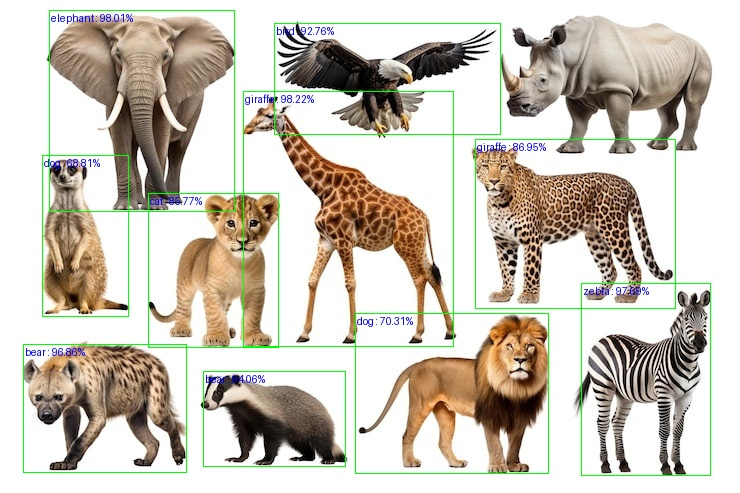

newyork.jpg
[{'name': 'person', 'percentage_probability': 91.02, 'box_points': [349, 463, 463, 716]}, {'name': 'person', 'percentage_probability': 87.53, 'box_points': [754, 405, 897, 757]}, {'name': 'person', 'percentage_probability': 84.97, 'box_points': [198, 466, 303, 730]}, {'name': 'person', 'percentage_probability': 82.15, 'box_points': [30, 444, 185, 733]}, {'name': 'person', 'percentage_probability': 80.81, 'box_points': [1003, 447, 1104, 762]}, {'name': 'person', 'percentage_probability': 79.63, 'box_points': [567, 420, 706, 770]}, {'name': 'person', 'percentage_probability': 76.68, 'box_points': [911, 482, 1005, 746]}, {'name': 'car', 'percentage_probability': 72.08, 'box_points': [852, 472, 946, 595]}, {'name': 'person', 'percentage_probability': 65.09, 'box_points': [177, 459, 257, 719]}]


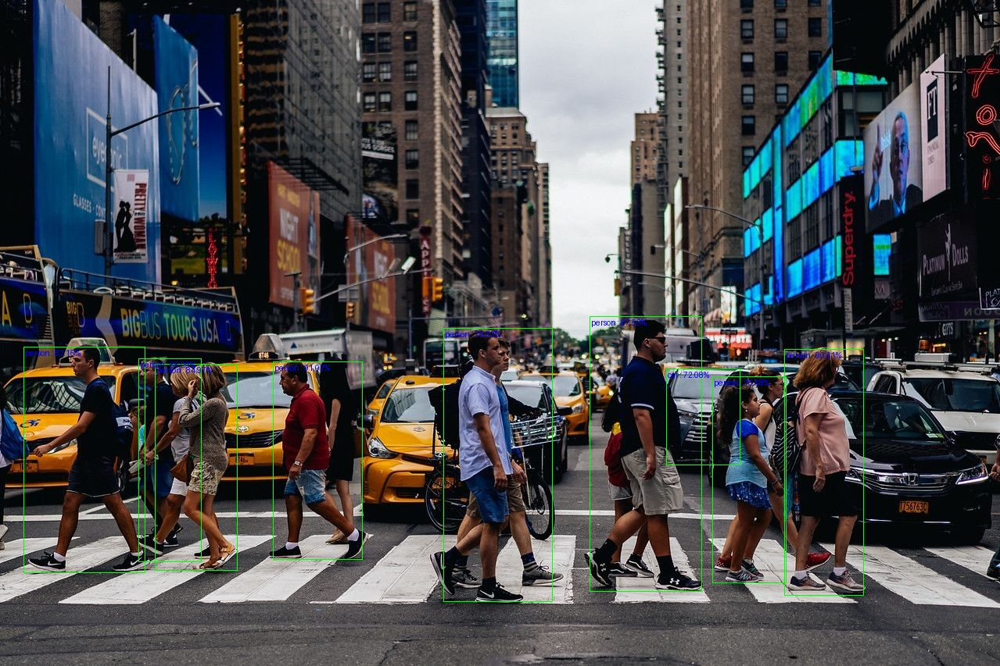

stationery.jpg
[{'name': 'scissors', 'percentage_probability': 66.35, 'box_points': [20, 210, 125, 551]}]


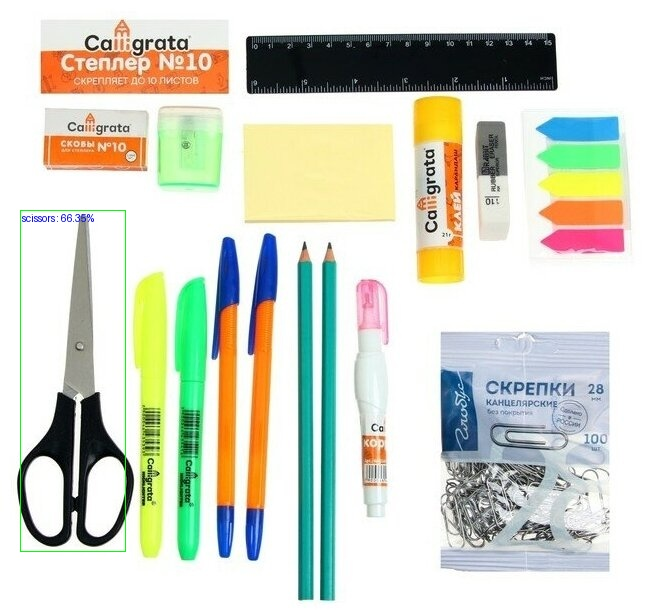

building.jpg
[{'name': 'person', 'percentage_probability': 83.06, 'box_points': [354, 671, 381, 756]}, {'name': 'person', 'percentage_probability': 82.24, 'box_points': [1111, 656, 1151, 764]}, {'name': 'truck', 'percentage_probability': 81.72, 'box_points': [567, 605, 697, 705]}, {'name': 'person', 'percentage_probability': 75.81, 'box_points': [1029, 666, 1067, 757]}, {'name': 'person', 'percentage_probability': 72.21, 'box_points': [329, 671, 358, 759]}, {'name': 'truck', 'percentage_probability': 65.23, 'box_points': [758, 618, 849, 708]}]


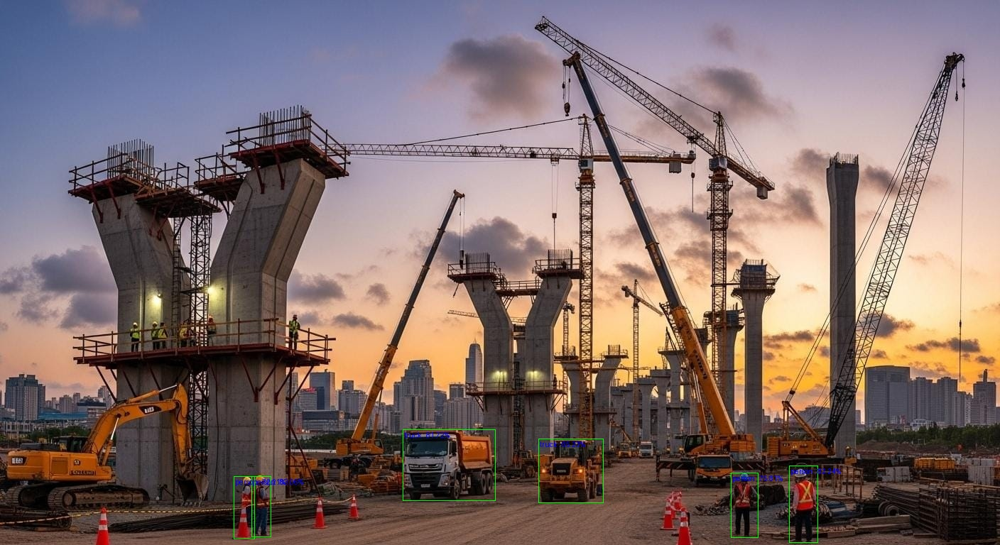

animals2.jpg
[{'name': 'cow', 'percentage_probability': 98.42, 'box_points': [10, 53, 454, 405]}, {'name': 'elephant', 'percentage_probability': 98.3, 'box_points': [495, 42, 917, 368]}, {'name': 'cat', 'percentage_probability': 98.07, 'box_points': [963, 386, 1260, 712]}, {'name': 'horse', 'percentage_probability': 97.43, 'box_points': [996, 14, 1217, 392]}, {'name': 'dog', 'percentage_probability': 92.66, 'box_points': [650, 382, 902, 704]}, {'name': 'sheep', 'percentage_probability': 90.36, 'box_points': [77, 410, 241, 700]}, {'name': 'bird', 'percentage_probability': 88.17, 'box_points': [342, 363, 491, 595]}, {'name': 'bird', 'percentage_probability': 79.17, 'box_points': [456, 425, 620, 703]}]


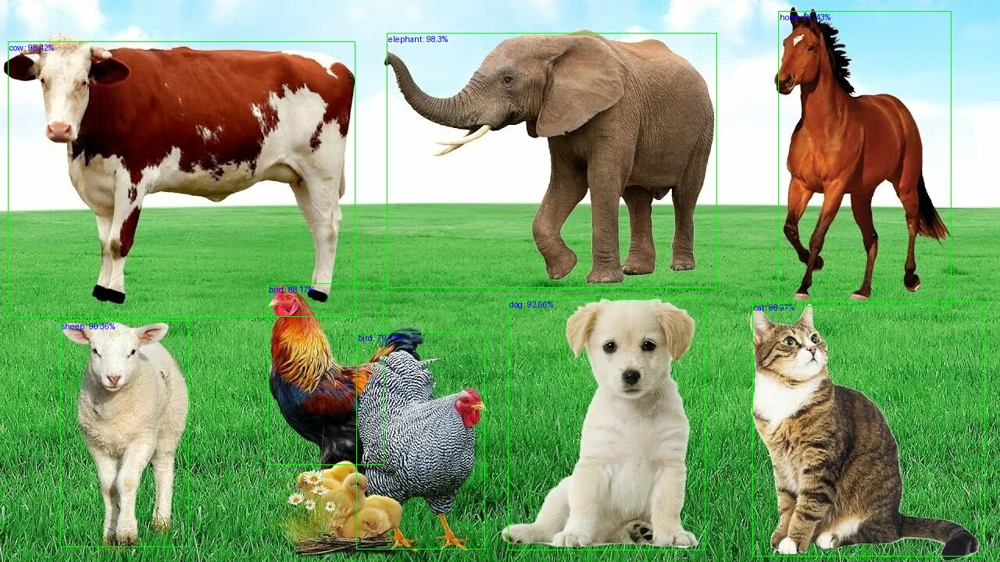

In [ ]:
urls1 = {
    "https://img.magnific.com/premium-photo/wildlife-animal-png-cut-out-set_53876-893795.jpg?semt=ais_hybrid&w=740&q=80": "animals1.jpg",
    "https://i.pinimg.com/originals/03/0d/90/030d901e4dce9ce73aad7767d569bec1.jpg": "newyork.jpg",
    "https://avatars.mds.yandex.net/get-mpic/4901709/img_id2456373075349747674.jpeg/orig": "stationery.jpg",
    "https://blagoystroystvo.ru/wp-content/uploads/2025/10/image-10-2.jpg": "building.jpg",
    "https://avatars.mds.yandex.net/i?id=efdceeb7f57eab557c12e905f1aadcef_l-5509039-images-thumbs&n=13": "animals2.jpg"
}

exec_path = os.getcwd()

detector = ObjectDetection()
detector.setModelTypeAsRetinaNet()
detector.setModelPath("/content/retinanet_resnet50_fpn_coco-eeacb38b.pth")
detector.loadModel()

for url_, file_ in urls1.items():
  detection(url_, file_, detector)

# Задание №2. Классификация изображений

2.1. Перейдите по ссылке из примера №2

2.2. Загрузите готовую модель для классификации изображений, отличную от той, что представлена в примере

2.3. Используя данную модель, обработе 5 изображений, которые относятся к разным классам

2.4. Сохраните полученные предсказания используемой модели

In [ ]:
!wget -q "https://github.com/OlafenwaMoses/ImageAI/releases/download/3.0.0-pretrained/densenet121-a639ec97.pth/" -O /content/densenet121-a639ec97.pth

In [ ]:
def classification(url, filename, predict_):
  req = urlopen(url)
  image_2 = np.asarray(bytearray(req.read()), dtype=np.uint8)
  image_2 = cv2.imdecode(image_2, -1)
  print(filename)
  result = {"image": filename, "predictions": []}
  predictions, probabilities = predict_.classifyImage((image_2), result_count=10)
  for eachPrediction, eachProbability in zip(predictions, probabilities):
    print(eachPrediction , " : " , eachProbability)
    result["predictions"].append({"class": eachPrediction, "probability": eachProbability})
  plt.figure(figsize=(8, 6))
  plt.imshow(cv2.cvtColor(image_2, cv2.COLOR_BGR2RGB))
  plt.show()

  return result

dog.jpg
whippet  :  36.2492
dalmatian  :  35.3634
Walker hound  :  10.1992
American Staffordshire terrier  :  4.0633
Weimaraner  :  3.8097
Italian greyhound  :  2.5055
basset  :  1.477
Great Dane  :  1.4099
English setter  :  1.1911
Staffordshire bullterrier  :  0.7329


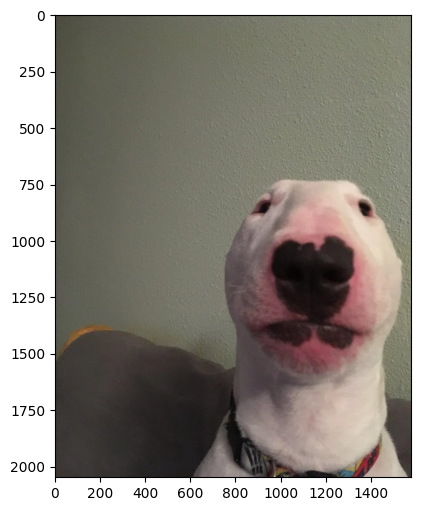

person.jpg
harmonica  :  42.3267
oxygen mask  :  7.4872
potter's wheel  :  5.0376
cellular telephone  :  4.3527
loupe  :  3.3304
sunscreen  :  3.2828
ocarina  :  2.9464
whistle  :  2.4972
water bottle  :  2.1173
lab coat  :  1.822


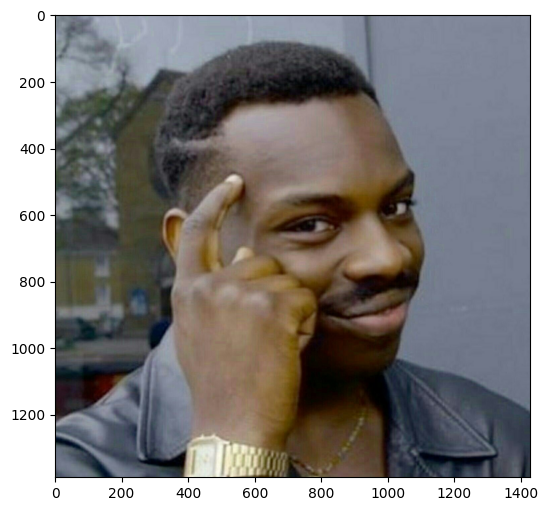

car.jpg
pickup  :  49.9542
jeep  :  14.9377
beach wagon  :  13.1746
tow truck  :  8.181
racer  :  6.3932
sports car  :  1.251
police van  :  1.1563
convertible  :  0.9575
cab  :  0.6713
minibus  :  0.6276


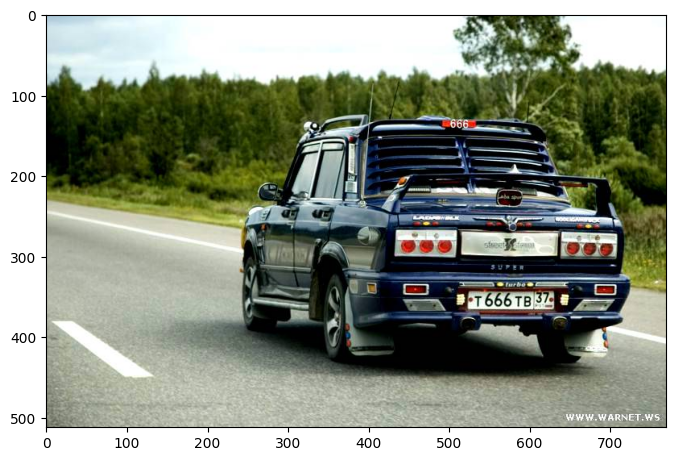

cat.jpg
Egyptian cat  :  25.6191
hare  :  10.624
Arctic fox  :  8.8166
Siamese cat  :  8.5326
wallaby  :  2.9143
wood rabbit  :  2.3455
toy terrier  :  2.0256
Japanese spaniel  :  1.7466
Eskimo dog  :  1.6286
Siberian husky  :  1.5222


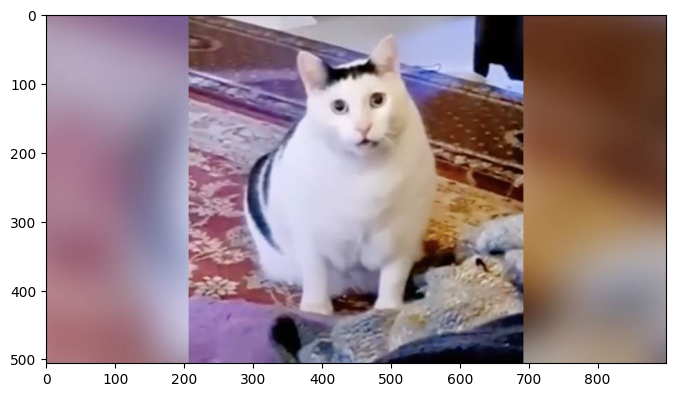

apple.jpg
croquet ball  :  61.9954
Granny Smith  :  17.5666
vase  :  6.5371
bell pepper  :  3.2249
dumbbell  :  1.3093
mouse  :  1.0291
maraca  :  0.8866
nail  :  0.7335
abacus  :  0.6015
mortar  :  0.524


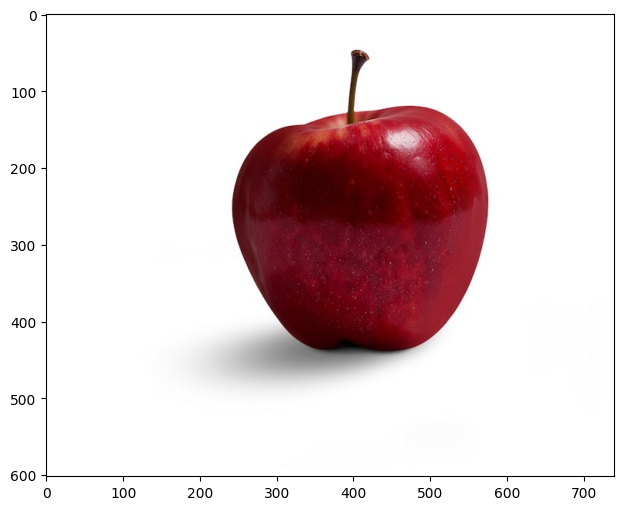

In [ ]:
import json

urls2 = {
    "https://avatars.mds.yandex.net/i?id=671855918f2780248dd740fad79a4b57_l-9099391-images-thumbs&n=13": "dog.jpg",
    "https://i.playground.ru/p/VDuLsgVUrCk9hy8r5nMOwA.jpeg": "person.jpg",
    "https://i3.guns.ru/forums/icons/forum_pictures/000865/865517.jpg": "car.jpg",
    "https://cdn.iz.ru/sites/default/files/styles/900x506/public/news-2021-12/13.32.31%201.jpg?itok=FMGKqpRs": "cat.jpg",
    "https://img.magnific.com/premium-psd/close-up-delicious-apple_23-2151868332.jpg?semt=ais_incoming&w=740&q=80": "apple.jpg"
}

execution_path = os.getcwd()

prediction = ImageClassification()
prediction.setModelTypeAsDenseNet121()
prediction.setModelPath(os.path.join(execution_path, "densenet121-a639ec97.pth"))
prediction.loadModel()

all_predictions = []

for url_, file_ in urls2.items():
  all_predictions.append(classification(url_, file_, prediction))

with open(os.path.join(execution_path, "classification_results.json"), "w", encoding="utf-8") as f:
    json.dump(all_predictions, f, ensure_ascii=False, indent=2)

# Задание №3. Детекция и трекинг объектов на видеопотоке

## 3.1. Подготовка набора данных:

* Найдите и загрузите из сети Интернет 5 видеофайлов с большим количеством разнородных объектов в кадре (например запись с камеры видеонаблюдения на шоссе и тд) длительностью от 10 секунд до 30 минуты (Также Вы можете скачать видеофайл большей длительности, а затем обрезать его в одном из [онлйан-сервисов](https://online-video-cutter.com/ru/?ysclid=lfjb8zk8er484677266).


* Для более оптимальной работы с видеофайлами, сожмите их, используя онлайн-сервисы. ([Например тут](https://compress-video-online.com/ru/ ))

## 3.2. Детекция и трекинг объектов на видеопотоке

3.2.1. [Ознакомьтесь с технической документацией](https://imageai.readthedocs.io/en/latest/video/index.html)

3.2.2. Загрузите готовую модель для детекции объектов

3.2.3. Используя данную модель, обработайте 5 видеофайлов (см. п. 3.1.)

3.2.4. Сохраните полученные видеофайлы

In [ ]:
from imageai.Detection import VideoObjectDetection

video_files = ["video1.mp4", "video2.mp4", "video3.mp4", "video4.mp4", "video5.mp4"]

execution_path = os.getcwd()
detector = VideoObjectDetection()
detector.setModelTypeAsYOLOv3()
detector.setModelPath( os.path.join(execution_path , "yolov3.pt"))
detector.loadModel()

for video_file in video_files:
  output_name = video_file.replace(".mp4", "_detected")

  video_path = detector.detectObjectsFromVideo(
      input_file_path=os.path.join(execution_path, video_file),
      output_file_path=os.path.join(execution_path, output_name),
      frames_per_second=20,
      log_progress=True
  )

Processing Frame :  1
Processing Frame :  2
Processing Frame :  3
Processing Frame :  4
Processing Frame :  5
Processing Frame :  6
Processing Frame :  7
Processing Frame :  8
Processing Frame :  9
Processing Frame :  10
Processing Frame :  11
Processing Frame :  12
Processing Frame :  13
Processing Frame :  14
Processing Frame :  15
Processing Frame :  16
Processing Frame :  17
Processing Frame :  18
Processing Frame :  19
Processing Frame :  20
Processing Frame :  21
Processing Frame :  22
Processing Frame :  23
Processing Frame :  24
Processing Frame :  25
Processing Frame :  26
Processing Frame :  27
Processing Frame :  28
Processing Frame :  29
Processing Frame :  30
Processing Frame :  31
Processing Frame :  32
Processing Frame :  33
Processing Frame :  34
Processing Frame :  35
Processing Frame :  36
Processing Frame :  37
Processing Frame :  38
Processing Frame :  39
Processing Frame :  40
Processing Frame :  41
Processing Frame :  42
Processing Frame :  43
Processing Frame :  

# Задание №4. Работа с видеопотоком вебкамеры

## 4.1. Ознакомиться с примерами создания фото и видео в среде Google Colab:



### **Устаналиваем зависимости:**

In [ ]:
# Импортируем необходимые библиотеки
import cv2  # OpenCV для обработки изображений
from google.colab import output  # Для взаимодействия с выводом в Google Colab
from google.colab.patches import cv2_imshow  # Специальная функция для отображения изображений в Colab
from IPython.display import display, Javascript  # Для выполнения JavaScript в ячейках Jupyter
from base64 import b64decode  # Для декодирования данных из base64
import numpy as np  # Для работы с массивами
import time  # Для работы со временем

### **Функция для создания фото:**

In [ ]:
def take_photo(filename='photo.jpg', quality=0.8):
    """
    Захватывает фотографию с веб-камеры пользователя и сохраняет ее в файл.

    Эта функция использует JavaScript для доступа к веб-камере через браузер,
    отображает видеопоток и позволяет пользователю сделать снимок, нажав кнопку "Capture".

    Параметры:
    filename (str): Имя файла для сохранения фотографии. По умолчанию 'photo.jpg'.
    quality (float): Качество сжатия JPEG от 0 до 1. По умолчанию 0.8.

    Возвращает:
    str: Имя файла, в который была сохранена фотография.

    Примечания:
    - Функция требует разрешения пользователя на доступ к веб-камере.
    - Работает только в среде, поддерживающей выполнение JavaScript (например, Google Colab).
    - Изображение сначала кодируется в формат base64, а затем декодируется и сохраняется как файл.
    """
    # Создаем JavaScript-код для захвата фото с веб-камеры
    js = Javascript('''
        async function takePhoto() {
            // Создаем элементы интерфейса
            const div = document.createElement('div');
            const capture = document.createElement('button');
            capture.textContent = 'Capture';
            div.appendChild(capture);
            const video = document.createElement('video');
            video.style.display = 'block';

            // Получаем доступ к веб-камере
            const stream = await navigator.mediaDevices.getUserMedia({video: true});
            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;
            await video.play();

            // Изменяем размер вывода, чтобы вместить видео
            google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

            // Ждем, пока пользователь нажмет кнопку "Capture"
            await new Promise((resolve) => capture.onclick = resolve);

            // Создаем canvas и захватываем кадр с видео
            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);

            // Останавливаем видеопоток и удаляем элементы интерфейса
            stream.getVideoTracks()[0].stop();
            div.remove();

            // Возвращаем изображение в формате base64
            return canvas.toDataURL('image/jpeg', %f);
        }
        ''' % quality)

    # Отображаем JavaScript-код
    display(js)

    # Выполняем функцию takePhoto() и получаем результат
    data = output.eval_js('takePhoto()')

    # Декодируем данные из base64
    binary = b64decode(data.split(',')[1])

    # Сохраняем изображение в файл
    with open(filename, 'wb') as f:
        f.write(binary)

    return filename

### **Функция для создания видео:**

In [ ]:
def record_video(filename='video.mp4', duration=5):
    """
    Записывает видео с веб-камеры пользователя и сохраняет его в файл.

    Эта функция использует JavaScript для доступа к веб-камере через браузер,
    записывает видео указанной продолжительности и сохраняет его в формате MP4.

    Параметры:
    filename (str): Имя файла для сохранения видео. По умолчанию 'video.mp4'.
    duration (int): Продолжительность записи в секундах. По умолчанию 5 секунд.

    Возвращает:
    str: Имя файла, в который было сохранено видео.

    Примечания:
    - Функция требует разрешения пользователя на доступ к веб-камере.
    - Работает только в среде, поддерживающей выполнение JavaScript (например, Google Colab).
    - Видео сначала кодируется в формат base64, а затем декодируется и сохраняется как файл MP4.
    - Запись начинается автоматически и заканчивается после указанной продолжительности.
    """
    # Создаем JavaScript-код для записи видео с веб-камеры
    js = Javascript('''
        async function recordVideo(duration) {
            // Создаем элемент видео
            const video = document.createElement('video');
            video.style.display = 'block';

            // Получаем доступ к веб-камере
            const stream = await navigator.mediaDevices.getUserMedia({video: true});
            document.body.appendChild(video);
            video.srcObject = stream;
            await video.play();

            // Изменяем размер вывода, чтобы вместить видео
            google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

            // Создаем объект MediaRecorder для записи видео
            const recorder = new MediaRecorder(stream);
            const chunks = [];
            recorder.ondataavailable = e => chunks.push(e.data);
            recorder.start();

            // Ждем указанную продолжительность
            await new Promise(resolve => setTimeout(resolve, duration * 1000));

            // Останавливаем запись и видеопоток
            recorder.stop();
            stream.getVideoTracks()[0].stop();
            video.remove();

            // Возвращаем записанное видео в формате base64
            return new Promise(resolve => {
                recorder.onstop = () => {
                    const blob = new Blob(chunks, {type: 'video/mp4'});
                    const reader = new FileReader();
                    reader.onload = e => resolve(e.target.result);
                    reader.readAsDataURL(blob);
                };
            });
        }
    ''')

    # Отображаем JavaScript-код
    display(js)

    # Выполняем функцию recordVideo() и получаем результат
    data = output.eval_js(f'recordVideo({duration})')

    # Декодируем данные из base64
    binary = b64decode(data.split(',')[1])

    # Сохраняем видео в файл
    with open(filename, 'wb') as f:
        f.write(binary)

    return filename

### **Пример работы:**

In [ ]:
# Сделать фото
photo_filename = take_photo()

# Записать видео длительностью 10 секунд
video_filename = record_video(duration=10)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4.2. Детекция и трекинг объектов на видеопотоке с вебкамеры


### 4.2.1. Используйте take_photo() для получения снимка и record_video() для создания 5-10 секундного видео с веб-камеры


In [ ]:
photo_filename = take_photo(filename='photo_from_webcamera.jpg', quality=0.8)
print(photo_filename)

video_filename = record_video(filename='video_from_webcamera.mp4', duration=10)
print(video_filename)

<IPython.core.display.Javascript object>

photo_from_webcamera.jpg


<IPython.core.display.Javascript object>

video_from_webcamera.mp4


### 4.2.2. Загрузите модель трекинга и детекции объектов


In [ ]:
execution_path = os.getcwd()

photo_detector = ObjectDetection()
photo_detector.setModelTypeAsYOLOv3()
photo_detector.setModelPath( os.path.join(execution_path , "yolov3.pt"))
photo_detector.loadModel()

video_detector = VideoObjectDetection()
video_detector.setModelTypeAsYOLOv3()
video_detector.setModelPath( os.path.join(execution_path , "yolov3.pt"))
video_detector.loadModel()

### 4.2.3. Реализуйте функции для обработки полученных фото и видео с помощью модели трекинга:
- Для фото: сохраните результат как "tracked_photo.jpg".
- Для видео: создайте новое видео с отмеченными объектами - "tracked_video.mp4".

person  :  99.96  :  [95, 78, 621, 469]
bottle  :  99.33  :  [449, 337, 469, 377]


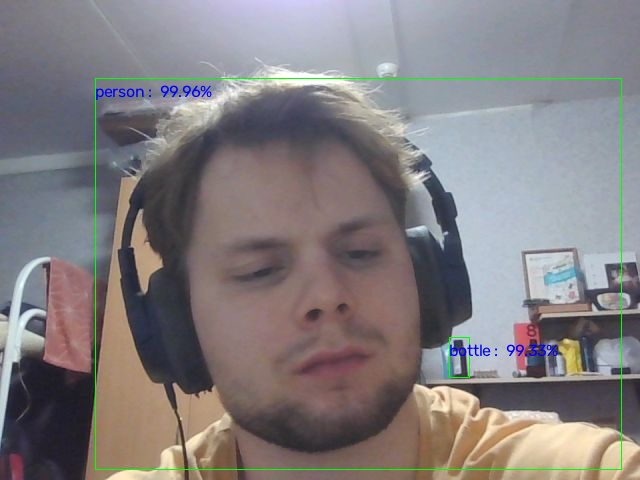

In [ ]:
input_photo = os.path.join(execution_path, "photo_from_webcamera.jpg")
output_photo = os.path.join(execution_path, "detected_photo.jpg")
detections = photo_detector.detectObjectsFromImage(
    input_image=input_photo,
    output_image_path=output_photo,
    minimum_percentage_probability=30,
    display_percentage_probability=True,
    display_object_name=True
)
for eachObject in detections:
    print(eachObject["name"], " : ", eachObject["percentage_probability"], " : ", eachObject["box_points"])
detected_photo = cv2.imread(output_photo)
if detected_photo is not None:
    cv2_imshow(detected_photo)

input_video = os.path.join(execution_path, "video_from_webcamera.mp4")
video_path = video_detector.detectObjectsFromVideo(
    input_file_path=input_video,
    output_file_path=os.path.join(execution_path, "detected_video"),
    frames_per_second=20,
    log_progress=False,
    minimum_percentage_probability=30
)

final_mp4 = os.path.join(execution_path, "detected_video.mp4")
!ffmpeg -y -i {video_path} -c:v libx264 -preset veryfast -crf 26 -pix_fmt yuv420p -r 20 -an -movflags +faststart {final_mp4} > /dev/null 2>&1